# Manuscript figures

Builds every manuscript figure and saves it to `figures/` as PDF and PNG.

1. **Setup**: load the model, simulation and plotting functions.
2. **Plotting parameters**: type sizes and the colour palette shared by every figure.
3. **Simulations**: load the cached runs from `sim_output/`, or rerun them.
4. **Figures 1–4** and the stylised mechanisms figure: one section per figure. Each figure's layout code is here, so edit it here;
   the panel functions it calls live in `paper_figures.py` and `stylised_mechanisms.py`.

`figure_style.save` checks every figure before saving it (standard font sizes, page width, no
text off the page or overlapping), so a layout change that breaks those rules fails loudly.

## 1. Setup

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

import figure_style as style
import paper_figures as pf
import stylised_mechanisms as sm
from metrics import plot_max_error, plot_normalised_pull, plot_time_outside_band

## 2. Plotting parameters

Type sizes and line widths come from `figure_style.apply()`. Figures are drawn at their printed
width (`style.PAGE_WIDTH` or `style.COLUMN_WIDTH` inches), so text prints at the same size in
every figure.

**Colours.** `style.PALETTE` maps colour names to hex values. Each module's `COLORS` maps a role
(e.g. `"herding"`, the colours of the herding levels in Figure 3) to palette names; roles
ending in `_ramp` are continuous colour maps through their palette colours, in order. Colours are
looked up when a figure is drawn, so an edit in the next cell changes every figure below it:

```python
style.PALETTE["ruby"] = "#C0392B"                    # recolour every use of ruby
pf.COLORS["herding"] = ("teal", "navy", "green", "orange", "ruby")   # new colours for one role
```

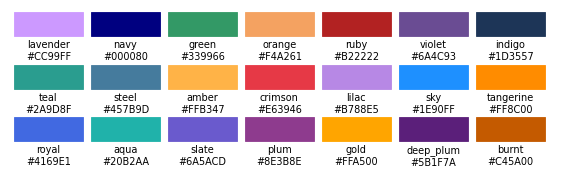

,module,role,palette names
0,paper_figures,whale_share,"(navy, green, orange, ruby)"
1,paper_figures,herding,"(teal, ruby, crimson, steel, violet)"
2,paper_figures,whale_valuation,"(steel, green, orange)"
3,paper_figures,rho_ramp,"(lavender, navy)"
4,paper_figures,herding_ramp,"(teal, amber, ruby)"
5,paper_figures,max_error_ramp,"(indigo, teal, amber)"
6,paper_figures,theory,"(navy, orange)"
7,paper_figures,price_up,tangerine
8,paper_figures,price_down,sky
9,paper_figures,outcome,crimson


In [2]:
style.apply()

# Edit the palette or the roles here (see above).


def show_palette(palette, per_row=7):
    """Swatches of every palette colour with its name and hex value."""
    rows = math.ceil(len(palette) / per_row)
    figure, ax = plt.subplots(figsize=(style.PAGE_WIDTH, 0.75 * rows))
    for index, (name, hex_value) in enumerate(palette.items()):
        row, column = divmod(index, per_row)
        ax.add_patch(plt.Rectangle((column, -row), 0.9, 0.45, color=hex_value))
        ax.text(column + 0.45, -row - 0.08, f"{name}\n{hex_value}", ha="center", va="top")
    ax.set(xlim=(-0.05, per_row), ylim=(-rows + 0.2, 0.5))
    ax.axis("off")
    plt.show()


show_palette(style.PALETTE)
pd.DataFrame(
    [("paper_figures", role, names) for role, names in pf.COLORS.items()]
    + [("stylised_mechanisms", role, names) for role, names in sm.COLORS.items()],
    columns=["module", "role", "palette names"],
)

## 3. Simulations

Each `load_*` function reads its cached runs from `sim_output/`, or reruns the simulations (and
updates the cache) when `RERUN = True` or the cache is missing. Rerunning everything takes about
25 minutes on `pf.N_WORKERS = 4` processes; the example run for Figure 1 takes a few seconds and
is never cached. The stylised mechanisms figure needs no simulations.

In [3]:
RERUN = False

# Figure 1
sweep = pf.load_sweep(RERUN)                                  # B: parameter sweeps
example = pf.example_run()                                    # A, C: one market, no whale

# Figure 2
whale_shares = pf.load_whale_shares(RERUN)                    # A-C: whale capital share ρ
profit_runs, traders = pf.load_profit_experiment(RERUN)       # D: trader wealth
valuation_paths = pf.load_valuations(RERUN)                   # E: whale valuation

# Figure 3
herding = pf.load_herding(RERUN)                              # A-C: herding strength h
herding_theory = pf.load_herding(RERUN, theory=True)          # A-C under the theory's assumptions
theory_a, theory_b = pf.load_theory_checks()                  # D-E: theory_checks/figdata_AB.json

# Figure 4
whale_herding = pf.load_whale_herding(RERUN)                  # A-B: whale against herding (~1.5 h to rerun)

## 4. Figure 1: the market without a whale

- **A** Market price, election outcome and average valuation in one example run.
- **B** Parameter sweeps: mean squared error, and (right) the peak price–fundamental cross-correlation.
- **C** Contracts traded per period and the capital locked in open contracts, same run.
- **D** Misclassification probability (analytic; does not depend on the market model).

`right_column` swaps B's right-hand column for `"lag"` (the lag at which the cross-correlation
peaks) or `"delay"` (the average response delay); `volume="new"` plots C as the net change in
contracts outstanding.

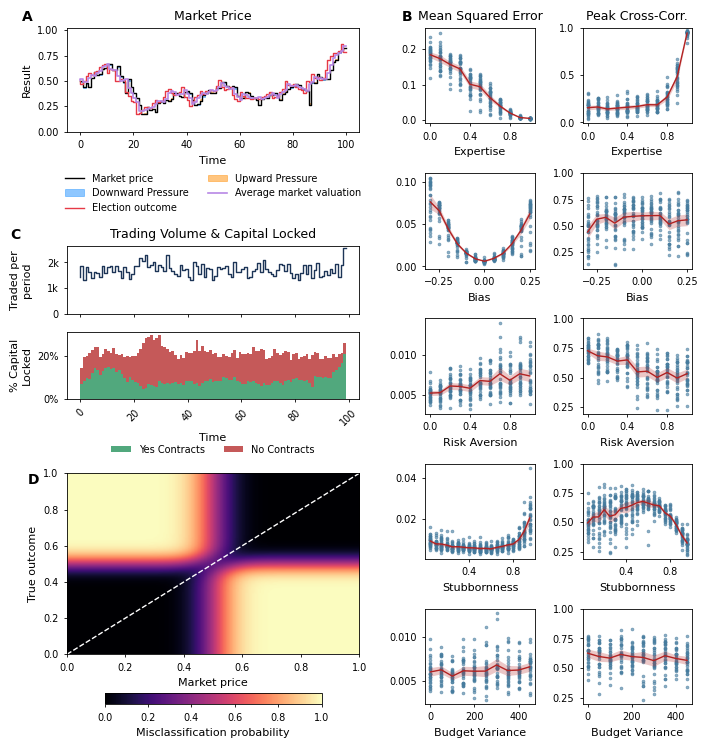

In [4]:
def figure1(right_column="cross_correlation", name="figure1_clob", volume="all"):
    # A wide left column (short panel A, C, D) and the parameter sweeps on the right.
    figure = plt.figure(figsize=(style.PAGE_WIDTH, 7.4), layout="constrained")
    left_fig, right_fig = figure.subfigures(1, 2, width_ratios=[1.15, 1], wspace=0.03)
    left = left_fig.add_gridspec(4, 1, height_ratios=[1.0, 0.65, 0.65, 1.75])
    ax_a = left_fig.add_subplot(left[0])
    ax_c = left_fig.add_subplot(left[1])
    ax_capital = left_fig.add_subplot(left[2], sharex=ax_c)
    ax_d = left_fig.add_subplot(left[3])
    pf.plot_market_price(example, ax_a)
    pf.plot_volume(example, ax_c, ax_capital, volume)
    pf.plot_misclassification(ax_d, left_fig)

    axes = right_fig.subplots(len(pf.SWEEPS), 2)
    for (ax_mse, ax_right), parameter in zip(axes, pf.SWEEPS):
        pf.plot_sweep_column(sweep, parameter, "mse", "", ax_mse)
        if right_column == "lag":
            pf.plot_lag_column(sweep, parameter, ax_right)
            ax_right.set_ylabel("")
        elif right_column == "delay":
            pf.plot_sweep_column(sweep, parameter, "response_delay", "", ax_right)
            ax_right.set_ylim(bottom=-0.2)
        else:
            pf.plot_sweep_column(sweep, parameter, "peak_cross_correlation", "", ax_right)
            ax_right.set_ylim(top=1)
        for ax in (ax_mse, ax_right):
            ax.xaxis.set_major_locator(plt.MaxNLocator(3))
    # What each column measures, once at its top, instead of a y-label on every row.
    right_titles = {"lag": "Best-Matching Lag", "delay": "Response Delay",
                    "cross_correlation": "Peak Cross-Corr."}
    axes[0, 0].set_title("Mean Squared Error")
    axes[0, 1].set_title(right_titles[right_column])

    style.label_panels(((ax_a, "A"), (axes[0, 0], "B"), (ax_c, "C"), (ax_d, "D")))
    pf.save(figure, name)


figure1()

Alternative right-hand columns for panel B (supplementary):

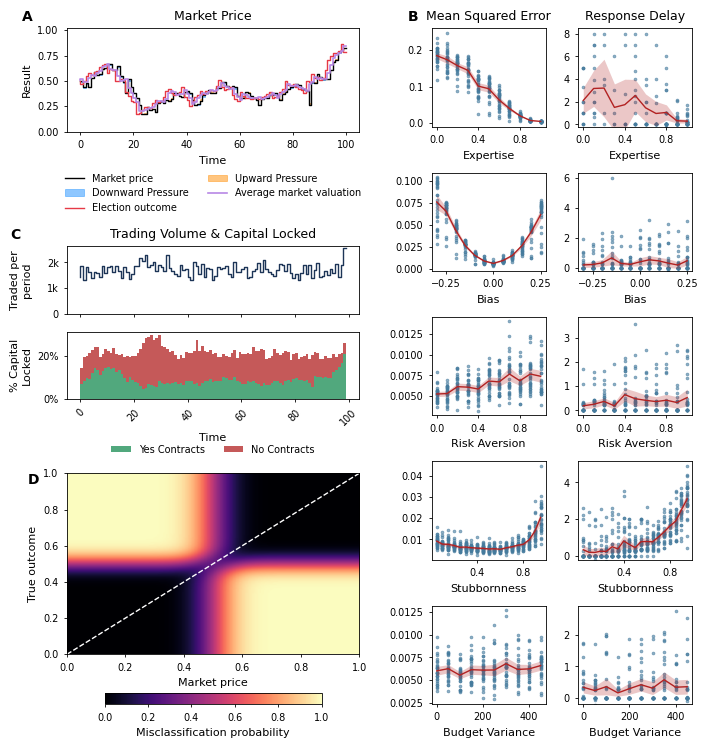

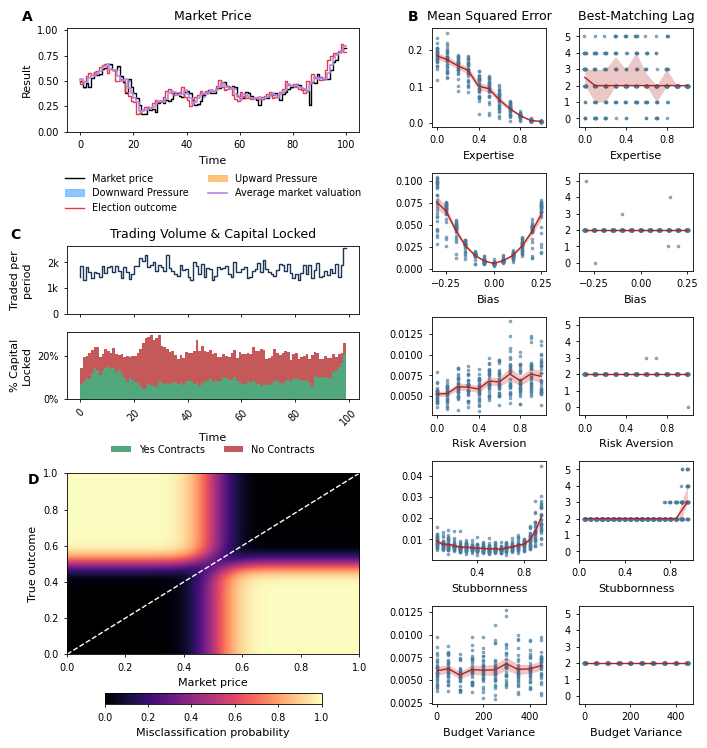

In [5]:
figure1("delay", "figure1_response_delay_clob")
figure1("lag", "figure1_best_lag_clob")

## 5. Figure 2: whale capital share

- **A** Maximum market error (P1), **B** time with error above ordinary noise (P3) and
  **C** pull toward the whale's valuation (P1b), by whale capital share ρ (500 runs per ρ).
- **D** Trader wealth by expertise and ρ.
- **E** (saved separately as `figure2e`) Mean price error after a whale shock, by whale valuation.

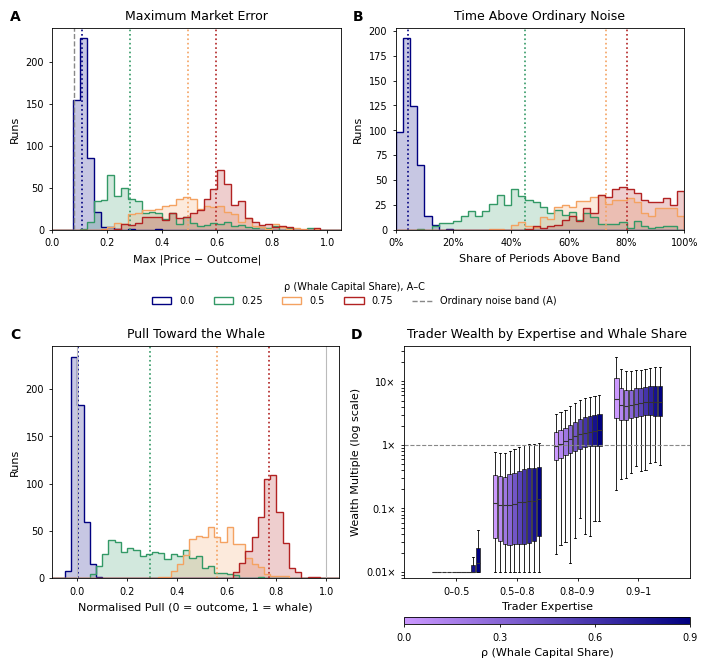

In [6]:
figure = plt.figure(figsize=(style.PAGE_WIDTH, 6.6), layout="constrained")
top, bottom = figure.subfigures(2, 1, height_ratios=[1, 1.1])
ax_a, ax_b = top.subplots(1, 2)
ax_c, ax_d = bottom.subplots(1, 2)
for ax, plot in ((ax_a, plot_max_error), (ax_b, plot_time_outside_band),
                 (ax_c, plot_normalised_pull)):
    plot(whale_shares, pf.RHO, ax, palette=pf.role_color("whale_share"))
    pf.style_axis(ax)
    ax.set_ylabel("Runs")
ax_a.set(title="Maximum Market Error", xlabel="Max |Price − Outcome|")
ax_b.set(title="Time Above Ordinary Noise", xlabel="Share of Periods Above Band")
ax_c.set(title="Pull Toward the Whale", xlabel="Normalised Pull (0 = outcome, 1 = whale)")

# A-C share colours: one legend, under the top row.
entries = pf.group_legend_entries((ax_a, ax_b, ax_c))
top.legend(list(entries.values()), list(entries), title="ρ (Whale Capital Share), A–C",
           loc="outside lower center", ncols=len(entries), frameon=False)

pf.plot_trader_returns(traders, ax_d, title="Trader Wealth by Expertise and Whale Share")
ax_d.set_ylabel("Wealth Multiple (log scale)")
pf.rho_colorbar(bottom, ax_d, list(pf.PROFIT_SHOWN_SHARES))
style.label_panels(((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_d, "D")))
pf.save(figure, "figure2")

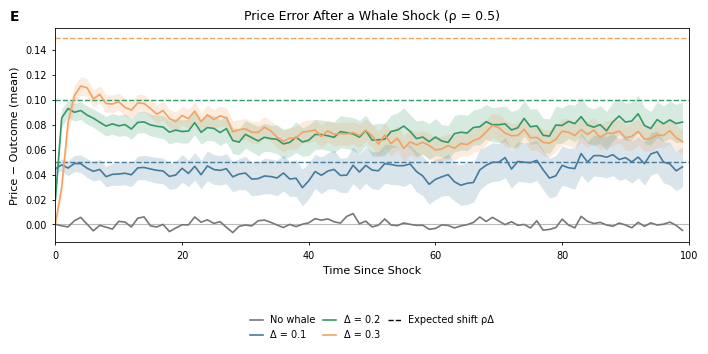

In [7]:
figure, ax_e = plt.subplots(figsize=(style.PAGE_WIDTH, 3.4), layout="constrained")
pf.plot_valuation_paths(valuation_paths, ax_e)
style.label_panels(((ax_e, "E"),))
pf.save(figure, "figure2e")

Supplementary: panel D's layout with trader risk aversion on the x-axis.

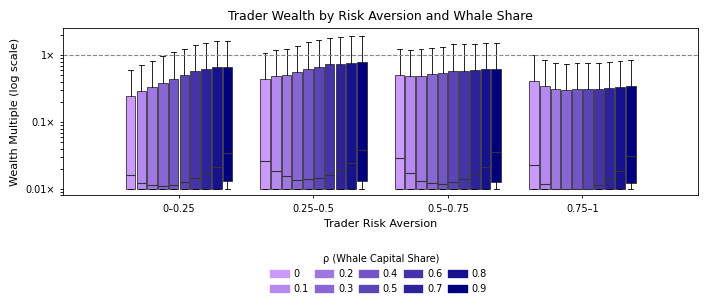

In [8]:
figure, ax = plt.subplots(figsize=(style.PAGE_WIDTH, 3.0), constrained_layout=True)
pf.plot_trader_returns(traders, ax, column="risk_aversion", groups=pf.RISK_AVERSION_GROUPS,
                       xlabel="Trader Risk Aversion",
                       title="Trader Wealth by Risk Aversion and Whale Share")
pf.save(figure, "trader_wealth_by_risk_aversion")

## 6. Figure 3: herding

- **A** Maximum error, **B** time above noise and **C** whale pull, one row per herding
  strength h: a whale with ρ = 0.3 trades from period 0 against 100 bettors with herding h
  (500 runs per h, each h judged against the band of its own no-whale runs).
- **D–E** The CLOB theory checks (`theory_checks/`): whale distortion without herding, and the
  share of the whale's misvaluation passed into the price against h.

Drawn twice: the original design (whale valuation 1, mixed risk aversion; `figure3b`) and the
theory's assumptions (whale valuation 0.7, log utility for everyone; `figure3b_theory`).

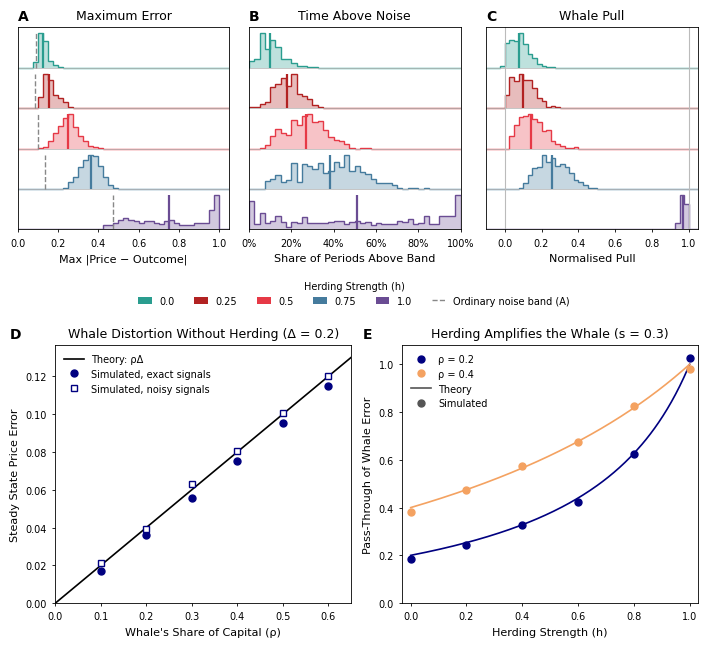

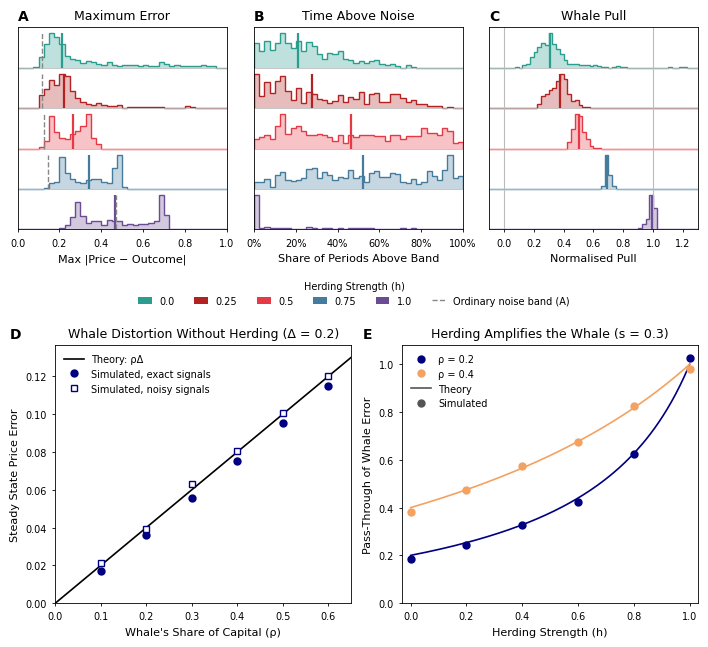

In [9]:
def figure3(metrics, name):
    heights = [2.9, 3.0]
    figure = plt.figure(figsize=(style.PAGE_WIDTH, sum(heights) + 0.5), layout="constrained")
    # Rows as separate subfigures, so each row is laid out on its own.
    top, bottom = figure.subfigures(2, 1, height_ratios=heights)
    axes = list(top.subplots(1, 3))
    panels = (
        (plot_max_error, "Maximum Error", "Max |Price − Outcome|"),
        (plot_time_outside_band, "Time Above Noise", "Share of Periods Above Band"),
        (plot_normalised_pull, "Whale Pull", "Normalised Pull"),
    )
    for ax, (plot, title, xlabel) in zip(axes, panels):
        plot(metrics, pf.HERDING, ax, palette=pf.role_color("herding"), layout="ridge",
             row_labels=False)
        ax.set(title=title, xlabel=xlabel, ylabel="")
        pf.style_axis(ax)

    # One legend under the row: group colours as filled boxes, then the ordinary band.
    entries = pf.group_legend_entries(axes)
    names = sorted(entries, key=lambda name: name.startswith("Ordinary"))
    handles = [entries[name] if name.startswith("Ordinary")
               else Patch(facecolor=entries[name].get_edgecolor(), edgecolor="none")
               for name in names]
    top.legend(handles, names, title="Herding Strength (h)", loc="outside lower center",
               ncols=len(names), frameon=False, handlelength=1.4)

    ax_d, ax_e = bottom.subplots(1, 2)
    pf.plot_theory_whale_share(ax_d, theory_a)
    pf.plot_theory_herding(ax_e, theory_b)
    style.label_panels([*zip(axes, "ABC"), (ax_d, "D"), (ax_e, "E")])
    pf.save(figure, name)


figure3(herding, "figure3b")
figure3(herding_theory, "figure3b_theory")

## 7. Figure 4: a whale against herding bettors

Simulation against the CLOB theory. Everyone has log utility, the true outcome is fixed at 0.5,
signals are exact and the whale (valuation 0.7) trades from period 0; 200 runs per condition.

- **A** Steady-state price error (mean over the last 50 periods) against the whale's initial
  capital share, by herding strength: theory (lines) and simulation (points, 95% intervals),
  stubbornness 0.1.
- **B** Mean maximum price error by herding strength and stubbornness, whale share 0.3.

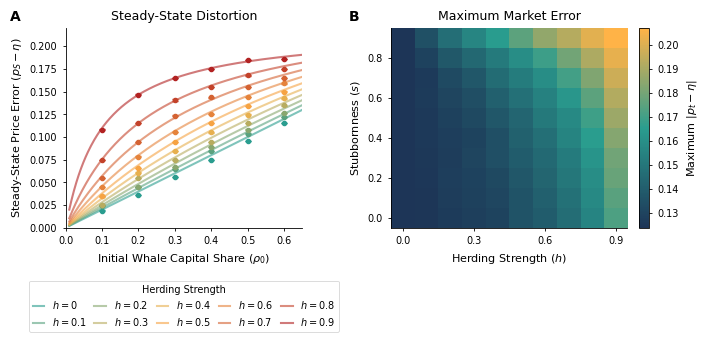

In [10]:
figure, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(style.PAGE_WIDTH, 3.3), layout="constrained")
pf.plot_steady_state_distortion(whale_herding, ax_a)
ax_a.legend(title="Herding Strength", loc="upper center", bbox_to_anchor=(0.5, -0.24), ncols=5,
            handlelength=1.2, columnspacing=0.8)
pf.plot_max_error_map(whale_herding, ax_b, figure)
for ax in (ax_a, ax_b):
    ax.spines[["top", "right"]].set_visible(False)
style.label_panels(((ax_a, "A"), (ax_b, "B")))
pf.save(figure, "figure4_whale_herding")

## 8. Stylised mechanisms

How the bettor parameters shape an agent's decisions (no simulations).

- **A** Risk aversion: the order a bettor with valuation 0.5 submits at each limit price (left),
  and how its reservation price moves once it holds a position (right).
- **B** Stubbornness: belief updating toward a noisy signal of the true outcome.
- **C** Expertise and bias: the distribution of signals a bettor receives.

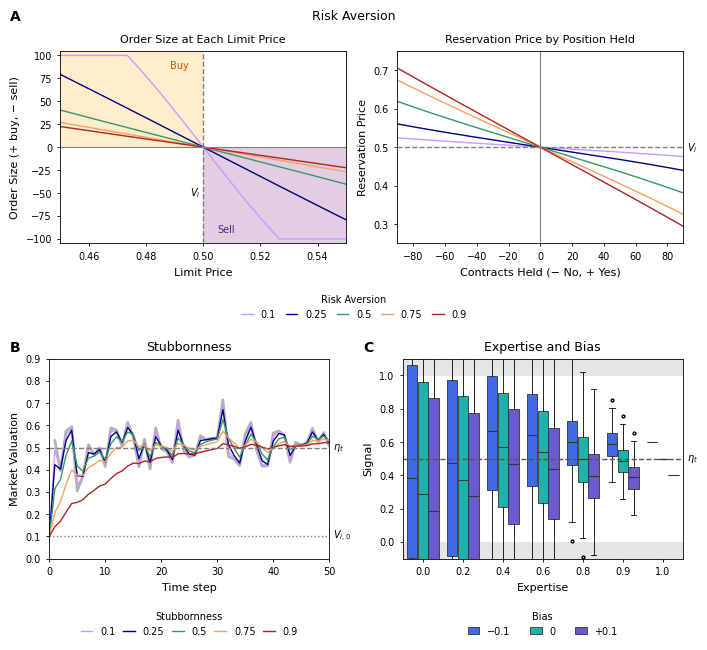

In [11]:
rng = np.random.default_rng(42)          # signals in B and C
# 2 x 2 grid: A (risk aversion: order size | reservation price) on top, B | C below.
figure = plt.figure(figsize=(style.PAGE_WIDTH, 6.4), layout="constrained")
top, bottom = figure.subfigures(2, 1, height_ratios=[1.05, 1])
ax_a, ax_a2 = top.subplots(1, 2)
ax_b, ax_c = bottom.subplots(1, 2)
sm.plot_order_size(ax_a)
sm.plot_reservation(ax_a2)
top.suptitle("Risk Aversion", fontsize=style.TITLE)
for ax in (ax_a, ax_a2):
    ax.title.set_fontsize(style.LABEL)            # subtitles under the shared title
top.legend(*ax_a.get_legend_handles_labels(), title="Risk Aversion",
           loc="outside lower center", ncols=len(sm.RISK_AVERSIONS), frameon=False,
           handlelength=1.2, columnspacing=1.0)
sm.plot_stubbornness(ax_b, rng)
sm.plot_signals(ax_c, rng)
ax_b.set_title("Stubbornness")
ax_c.set_title("Expertise and Bias")
ax_b.set_ylabel("Market Valuation")
style.label_panels(((ax_a, "A"), (ax_b, "B"), (ax_c, "C")))
pf.save(figure, "stylised_mechanisms_clob")